# Spotify Recommendation System — Exploratory Data Analysis

This notebook profiles `spotify dataset.csv` for data quality, distributions, relationships, and content-based recommendation readiness. It only reads the CSV; the source dataset and existing notebooks are never modified.

## tl;dr

The cell below calculates a live, data-backed summary each time the notebook runs. The detailed checks and charts that support it are in the sections that follow.

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid', context='notebook', palette='deep')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.titleweight'] = 'bold'

DATA_PATH = Path('spotify dataset.csv')
RANDOM_STATE = 42
assert DATA_PATH.exists(), f'Could not find {DATA_PATH.resolve()}'

# Keep the source frame unchanged. All analysis uses a separate in-memory copy.
raw_df = pd.read_csv(DATA_PATH)
index_like_columns = [
    column for column in raw_df.columns
    if str(column).strip() == '' or str(column).lower().startswith('unnamed')
]
df = raw_df.drop(columns=index_like_columns).copy()
analysis_df = df.assign(duration_min=df['duration_ms'] / 60_000)

missing_cells = int(df.isna().sum().sum())
exact_duplicate_rows = int(df.duplicated().sum())
duplicate_track_id_rows = int(df['track_id'].duplicated().sum())
genre_counts = df['track_genre'].value_counts(dropna=False)
audio_feature_columns = [
    'danceability', 'energy', 'loudness', 'speechiness', 'acousticness',
    'instrumentalness', 'liveness', 'valence', 'tempo'
]
audio_feature_columns = [column for column in audio_feature_columns if column in df.columns]
audio_missing = int(df[audio_feature_columns].isna().sum().sum())

display(Markdown(
    f"- **Dataset:** {len(df):,} rows × {df.shape[1]:,} analysis columns; the export-only index column `{', '.join(index_like_columns) or 'none'}` is excluded only in memory.\n"
    f"- **Coverage:** {df['track_genre'].nunique():,} genres with {genre_counts.min():,}–{genre_counts.max():,} tracks per genre; this is a deliberately balanced genre sample, not organic catalog share.\n"
    f"- **Quality flags:** {missing_cells:,} missing values, {exact_duplicate_rows:,} exact duplicate rows, and {duplicate_track_id_rows:,} repeated track-ID rows. Repeated IDs need inspection before using `track_id` as a unique item key.\n"
    f"- **Recommendation readiness:** audio-feature completeness has {audio_missing:,} missing cells. The dataset supports content and genre exploration, but has no users, events, timestamps, impressions, or feedback for personalised-ranking evaluation."
))

- **Dataset:** 114,000 rows × 20 analysis columns; the export-only index column `Unnamed: 0` is excluded only in memory.
- **Coverage:** 114 genres with 1,000–1,000 tracks per genre; this is a deliberately balanced genre sample, not organic catalog share.
- **Quality flags:** 3 missing values, 450 exact duplicate rows, and 24,259 repeated track-ID rows. Repeated IDs need inspection before using `track_id` as a unique item key.
- **Recommendation readiness:** audio-feature completeness has 0 missing cells. The dataset supports content and genre exploration, but has no users, events, timestamps, impressions, or feedback for personalised-ranking evaluation.

## Context & Methods

### Questions answered

1. Is the file structurally suitable for exploratory analysis and a content-based recommender?
2. What are the important numeric, categorical, and popularity distributions?
3. Which data-quality risks, outliers, duplicates, and feature relationships need attention before modelling?

### Key assumptions

- One row is treated as a track record, but `track_id` is checked rather than assumed to be a unique primary key.
- `artists` may contain multiple artists in one string, so artist counts refer to the literal field rather than individual artists.
- `popularity` is explored as an available catalog attribute, not treated as user preference or a causal outcome.
- The CSV is read once and is not written, cleaned in place, or overwritten. Derived fields such as `duration_min` exist only in memory.

## Data

### 1. Source, shape, and schema

In [2]:
print(f'Source: {DATA_PATH.resolve()}')
print(f'Raw shape: {raw_df.shape[0]:,} rows × {raw_df.shape[1]:,} columns')
print(f'Analysis shape: {df.shape[0]:,} rows × {df.shape[1]:,} columns')
print('Index-like columns excluded from analysis only:', index_like_columns if index_like_columns else 'None')

schema = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'non_null': df.notna().sum(),
    'missing': df.isna().sum(),
    'unique_values': df.nunique(dropna=True),
})
schema['missing_rate_%'] = (100 * schema['missing'] / len(df)).round(3)
display(schema)
display(df.head(5))

Source: E:\Spotify\spotify dataset.csv
Raw shape: 114,000 rows × 21 columns
Analysis shape: 114,000 rows × 20 columns
Index-like columns excluded from analysis only: ['Unnamed: 0']


,dtype,non_null,missing,unique_values,missing_rate_%
track_id,object,114000,0,89741,0.000
artists,object,113999,1,31437,0.001
album_name,object,113999,1,46589,0.001
track_name,object,113999,1,73608,0.001
popularity,int64,114000,0,101,0.000
duration_ms,int64,114000,0,50697,0.000
explicit,bool,114000,0,2,0.000
danceability,float64,114000,0,1174,0.000
energy,float64,114000,0,2083,0.000
key,int64,114000,0,12,0.000


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


## Results

### 2. Data quality and grain checks

In [3]:
missingness = (
    df.isna().sum()
    .to_frame('missing_values')
    .assign(missing_rate_pct=lambda x: (100 * x['missing_values'] / len(df)).round(3))
    .sort_values(['missing_values', 'missing_rate_pct'], ascending=False)
)
display(missingness)

quality_overview = pd.DataFrame({
    'check': [
        'Rows', 'Columns used for analysis', 'Exact duplicate rows',
        'Rows with repeated track_id', 'Unique track_id values',
        'track_id values appearing in multiple genres', 'Missing cells'
    ],
    'value': [
        len(df), df.shape[1], exact_duplicate_rows, duplicate_track_id_rows,
        df['track_id'].nunique(),
        int((df.groupby('track_id')['track_genre'].nunique() > 1).sum()),
        missing_cells
    ]
})
display(quality_overview)

,missing_values,missing_rate_pct
artists,1,0.001
album_name,1,0.001
track_name,1,0.001
track_id,0,0.000
popularity,0,0.000
duration_ms,0,0.000
explicit,0,0.000
danceability,0,0.000
energy,0,0.000
key,0,0.000


,check,value
0,Rows,114000
1,Columns used for analysis,20
2,Exact duplicate rows,450
3,Rows with repeated track_id,24259
4,Unique track_id values,89741
5,track_id values appearing in multiple genres,16299
6,Missing cells,3


In [4]:
repeated_id_records = (
    df[df['track_id'].duplicated(keep=False)]
    .sort_values(['track_id', 'track_genre'])
)

repeated_id_summary = (
    repeated_id_records.groupby('track_id', as_index=False)
    .agg(
        rows=('track_id', 'size'),
        genres=('track_genre', 'nunique'),
        track_names=('track_name', 'nunique'),
        artists=('artists', 'nunique')
    )
    .sort_values(['rows', 'genres'], ascending=False)
)

print('Sample of repeated track IDs. Repeated IDs may reflect genre-labelled copies, not necessarily corrupt records.')
display(repeated_id_summary.head(15))

if exact_duplicate_rows:
    print('Sample exact duplicate rows:')
    display(df[df.duplicated(keep=False)].sort_values('track_id').head(10))

Sample of repeated track IDs. Repeated IDs may reflect genre-labelled copies, not necessarily corrupt records.


,track_id,rows,genres,track_names,artists
13819,6S3JlDAGk3uu3NtZbPnuhS,9,9,1,1
4797,2Ey6v4Sekh3Z0RUSISRosD,8,8,1,1
5866,2kkvB3RNRzwjFdGhaUA0tz,8,8,1,1
310,08kTa3SL9sV6Iy8KLKtGql,7,7,1,1
941,0RSGPiykniIg8m7JhiAVv7,7,7,1,1
1204,0YLSjVxSb5FT1Bo8Tnxr8j,7,7,1,1
1421,0e5LcankE0UyJUuCoq1uH2,7,7,1,1
2786,1Gqpa08T7eBAvPQj9O9L2Q,7,7,1,1
5511,2aaClnypAakdAmLw74JXxB,7,7,1,1
6054,2qgXrzJsry4KgYoJCpuaul,7,7,1,1


Sample exact duplicate rows:


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
52766,00JZ83w0Qm09f4PwWj06sM,George Jones,With Love,A Good Year For The Roses,12,190546,False,0.491,0.334,11,-9.684,1,0.0287,0.659,0.000016,0.116,0.2490,91.674,4,honky-tonk
52714,00JZ83w0Qm09f4PwWj06sM,George Jones,With Love,A Good Year For The Roses,12,190546,False,0.491,0.334,11,-9.684,1,0.0287,0.659,0.000016,0.116,0.2490,91.674,4,honky-tonk
39275,02KmEChUwcjxG3G29kbLFT,Hans Zimmer;Henning Lohner;Martin Tillman;Fiac...,Hans Zimmer: Epic Scores,Shelter Mountain,16,250520,False,0.144,0.262,9,-21.228,1,0.0641,0.876,0.755000,0.144,0.0345,94.430,4,german
39307,02KmEChUwcjxG3G29kbLFT,Hans Zimmer;Henning Lohner;Martin Tillman;Fiac...,Hans Zimmer: Epic Scores,Shelter Mountain,16,250520,False,0.144,0.262,9,-21.228,1,0.0641,0.876,0.755000,0.144,0.0345,94.430,4,german
93376,02MRylJ1WAgxzdqfNfdIsR,Oleg Pogudin,Любовь и разлука. Песни Исаака Шварца,"Город пышный, город бедный",0,114600,False,0.446,0.121,4,-12.737,0,0.0414,0.937,0.000000,0.125,0.1800,107.573,3,romance
93331,02MRylJ1WAgxzdqfNfdIsR,Oleg Pogudin,Любовь и разлука. Песни Исаака Шварца,"Город пышный, город бедный",0,114600,False,0.446,0.121,4,-12.737,0,0.0414,0.937,0.000000,0.125,0.1800,107.573,3,romance
16747,03B8ZXUmuDpf59j5PIMFHq,Wolfgang Amadeus Mozart;Heinz Holliger;Academy...,Mozart - All Day Classics,"Ma che vi fece... Sperai vicino, K.368: 1. And...",7,86160,False,0.290,0.049,5,-24.072,1,0.0555,0.980,0.753000,0.108,0.1140,76.473,4,classical
16947,03B8ZXUmuDpf59j5PIMFHq,Wolfgang Amadeus Mozart;Heinz Holliger;Academy...,Mozart - All Day Classics,"Ma che vi fece... Sperai vicino, K.368: 1. And...",7,86160,False,0.290,0.049,5,-24.072,1,0.0555,0.980,0.753000,0.108,0.1140,76.473,4,classical
16723,040CvqW0wo3b77EBRfgC14,Wolfgang Amadeus Mozart;Isabelle van Keulen;Ro...,Mozart - A Classical Dawn,Andante and allegretto for Piano and Violin in...,6,84653,False,0.446,0.106,7,-21.427,1,0.0459,0.987,0.696000,0.101,0.8440,157.273,4,classical
16923,040CvqW0wo3b77EBRfgC14,Wolfgang Amadeus Mozart;Isabelle van Keulen;Ro...,Mozart - A Classical Dawn,Andante and allegretto for Piano and Violin in...,6,84653,False,0.446,0.106,7,-21.427,1,0.0459,0.987,0.696000,0.101,0.8440,157.273,4,classical


In [5]:
# Domain checks are descriptive: values are flagged, never changed.
bounded_columns = {
    'popularity': (0, 100),
    'danceability': (0, 1), 'energy': (0, 1), 'speechiness': (0, 1),
    'acousticness': (0, 1), 'instrumentalness': (0, 1),
    'liveness': (0, 1), 'valence': (0, 1),
    'key': (0, 11), 'mode': (0, 1)
}
validity_rows = []
for column, (lower, upper) in bounded_columns.items():
    if column in df.columns:
        observed = df[column].dropna()
        invalid = int(((observed < lower) | (observed > upper)).sum())
        validity_rows.append({
            'column': column, 'expected_range': f'[{lower}, {upper}]',
            'observed_min': observed.min(), 'observed_max': observed.max(),
            'outside_expected_range': invalid
        })

validity_rows.extend([
    {
        'column': 'duration_ms', 'expected_range': '> 0',
        'observed_min': df['duration_ms'].min(), 'observed_max': df['duration_ms'].max(),
        'outside_expected_range': int((df['duration_ms'] <= 0).sum())
    },
    {
        'column': 'tempo', 'expected_range': '> 0',
        'observed_min': df['tempo'].min(), 'observed_max': df['tempo'].max(),
        'outside_expected_range': int((df['tempo'] <= 0).sum())
    }
])

validity_report = pd.DataFrame(validity_rows)
display(validity_report)
display(pd.DataFrame({
    'check': ['unexpected time_signature', 'non-boolean explicit values'],
    'count': [
        int((~df['time_signature'].isin([0, 1, 3, 4, 5])).sum()),
        int((~df['explicit'].isin([True, False])).sum())
    ]
}))

,column,expected_range,observed_min,observed_max,outside_expected_range
0,popularity,"[0, 100]",0.0,100.000,0
1,danceability,"[0, 1]",0.0,0.985,0
2,energy,"[0, 1]",0.0,1.000,0
3,speechiness,"[0, 1]",0.0,0.965,0
4,acousticness,"[0, 1]",0.0,0.996,0
5,instrumentalness,"[0, 1]",0.0,1.000,0
6,liveness,"[0, 1]",0.0,1.000,0
7,valence,"[0, 1]",0.0,0.995,0
8,key,"[0, 11]",0.0,11.000,0
9,mode,"[0, 1]",0.0,1.000,0


,check,count
0,unexpected time_signature,0
1,non-boolean explicit values,0


### 3. Numeric summaries, outliers, and distributions

The continuous-feature charts use the full available values. IQR flags are screening signals, not automatic evidence of bad data; musical attributes can be legitimately skewed or long-tailed.

In [6]:
continuous_features = [
    'popularity', 'duration_min', 'danceability', 'energy', 'loudness',
    'speechiness', 'acousticness', 'instrumentalness', 'liveness',
    'valence', 'tempo'
]
continuous_features = [column for column in continuous_features if column in analysis_df.columns]

numeric_summary = analysis_df[continuous_features].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T
numeric_summary['skew'] = analysis_df[continuous_features].skew()
display(numeric_summary.round(3))

outlier_rows = []
for column in continuous_features:
    series = analysis_df[column].dropna()
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flagged = int(((series < lower) | (series > upper)).sum())
    outlier_rows.append({
        'feature': column, 'q1': q1, 'q3': q3, 'iqr': iqr,
        'lower_fence': lower, 'upper_fence': upper,
        'iqr_flagged_rows': flagged, 'iqr_flagged_rate_pct': 100 * flagged / len(series)
    })
outlier_report = pd.DataFrame(outlier_rows).sort_values('iqr_flagged_rate_pct', ascending=False)
display(outlier_report.round(3))

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,skew
popularity,114000.0,33.239,22.305,0.000,0.000,0.000,17.000,35.000,50.000,69.000,80.000,100.000,0.046
duration_min,114000.0,3.800,1.788,0.000,1.078,1.949,2.901,3.548,4.358,6.453,8.848,87.288,11.195
danceability,114000.0,0.567,0.174,0.000,0.134,0.250,0.456,0.580,0.695,0.824,0.901,0.985,-0.399
energy,114000.0,0.641,0.252,0.000,0.031,0.154,0.472,0.685,0.854,0.969,0.993,1.000,-0.597
loudness,114000.0,-8.259,5.029,-49.531,-27.788,-18.067,-10.013,-7.004,-5.003,-2.974,-1.634,4.532,-2.007
speechiness,114000.0,0.085,0.106,0.000,0.025,0.028,0.036,0.049,0.084,0.268,0.507,0.965,4.648
acousticness,114000.0,0.315,0.333,0.000,0.000,0.000,0.017,0.169,0.598,0.948,0.992,0.996,0.727
instrumentalness,114000.0,0.156,0.310,0.000,0.000,0.000,0.000,0.000,0.049,0.904,0.955,1.000,1.734
liveness,114000.0,0.214,0.190,0.000,0.041,0.061,0.098,0.132,0.273,0.681,0.946,1.000,2.106
valence,114000.0,0.474,0.259,0.000,0.035,0.071,0.260,0.464,0.683,0.911,0.965,0.995,0.115


,feature,q1,q3,iqr,lower_fence,upper_fence,iqr_flagged_rows,iqr_flagged_rate_pct
7,instrumentalness,0.000,0.049,0.049,-0.074,0.123,25246,22.146
5,speechiness,0.036,0.084,0.049,-0.037,0.157,13211,11.589
8,liveness,0.098,0.273,0.175,-0.164,0.536,8642,7.581
4,loudness,-10.013,-5.003,5.010,-17.528,2.512,6173,5.415
1,duration_min,2.901,4.358,1.457,0.715,6.544,5618,4.928
2,danceability,0.456,0.695,0.239,0.098,1.053,620,0.544
10,tempo,99.219,140.071,40.852,37.940,201.349,617,0.541
0,popularity,17.000,50.000,33.000,-32.500,99.500,2,0.002
3,energy,0.472,0.854,0.382,-0.101,1.427,0,0.000
6,acousticness,0.017,0.598,0.581,-0.855,1.470,0,0.000


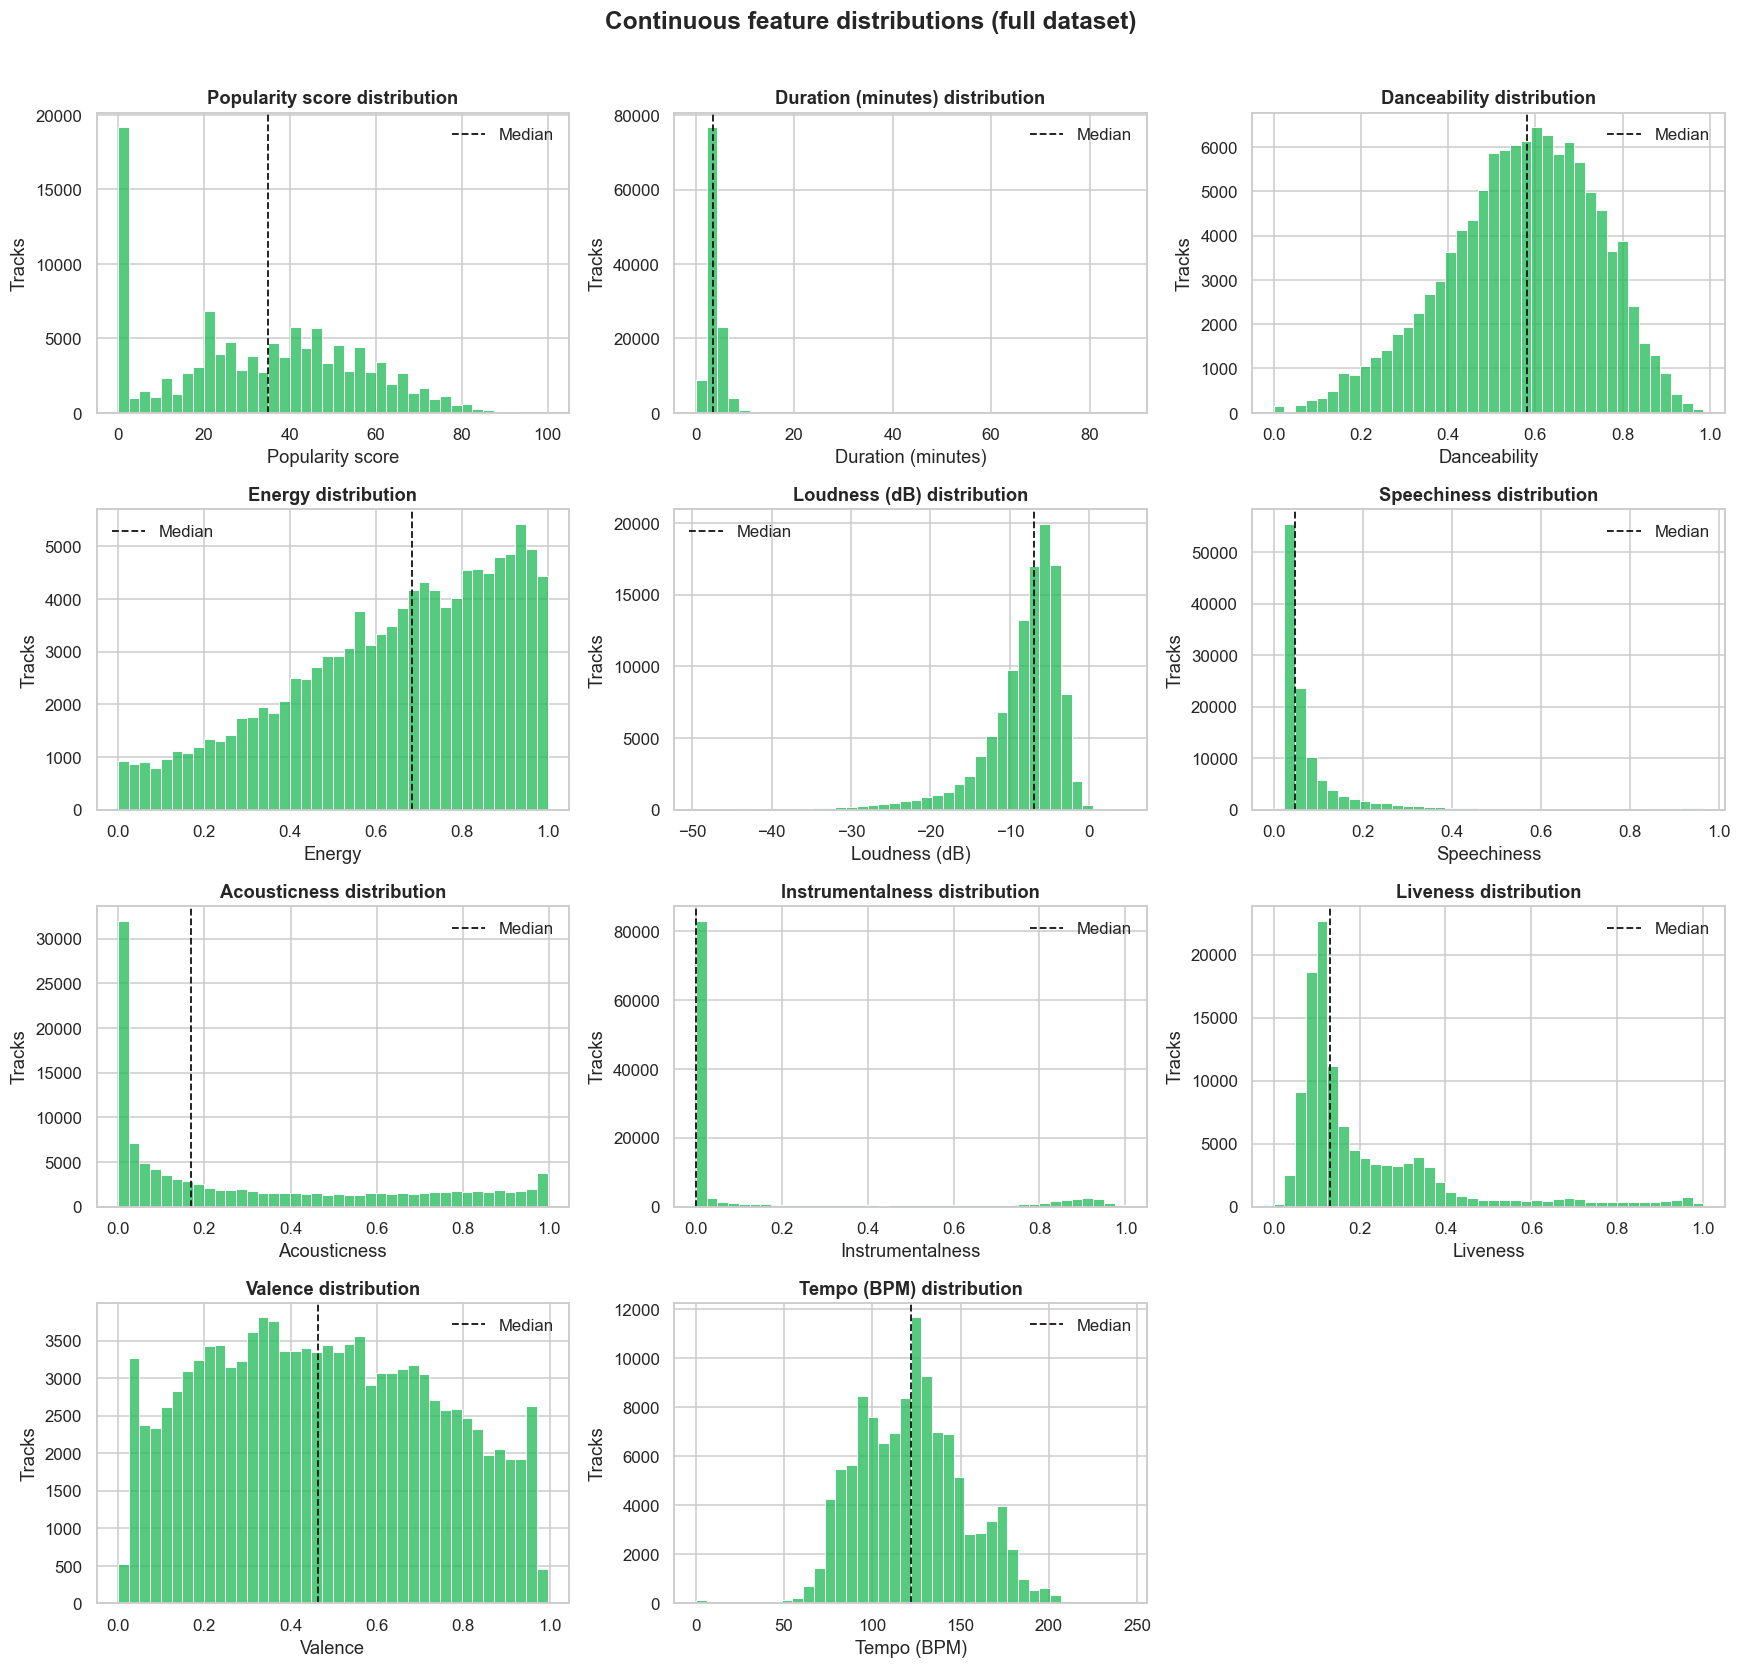

In [7]:
feature_labels = {
    'popularity': 'Popularity score', 'duration_min': 'Duration (minutes)',
    'danceability': 'Danceability', 'energy': 'Energy', 'loudness': 'Loudness (dB)',
    'speechiness': 'Speechiness', 'acousticness': 'Acousticness',
    'instrumentalness': 'Instrumentalness', 'liveness': 'Liveness',
    'valence': 'Valence', 'tempo': 'Tempo (BPM)'
}

fig, axes = plt.subplots(4, 3, figsize=(16, 15))
for axis, column in zip(axes.flat, continuous_features):
    sns.histplot(data=analysis_df, x=column, bins=40, color='#1DB954', edgecolor='white', ax=axis)
    axis.axvline(analysis_df[column].median(), color='#191414', linestyle='--', linewidth=1.2, label='Median')
    axis.set_title(f"{feature_labels.get(column, column)} distribution")
    axis.set_xlabel(feature_labels.get(column, column))
    axis.set_ylabel('Tracks')
    axis.legend(frameon=False)
for axis in axes.flat[len(continuous_features):]:
    axis.remove()
fig.suptitle('Continuous feature distributions (full dataset)', y=1.01, fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

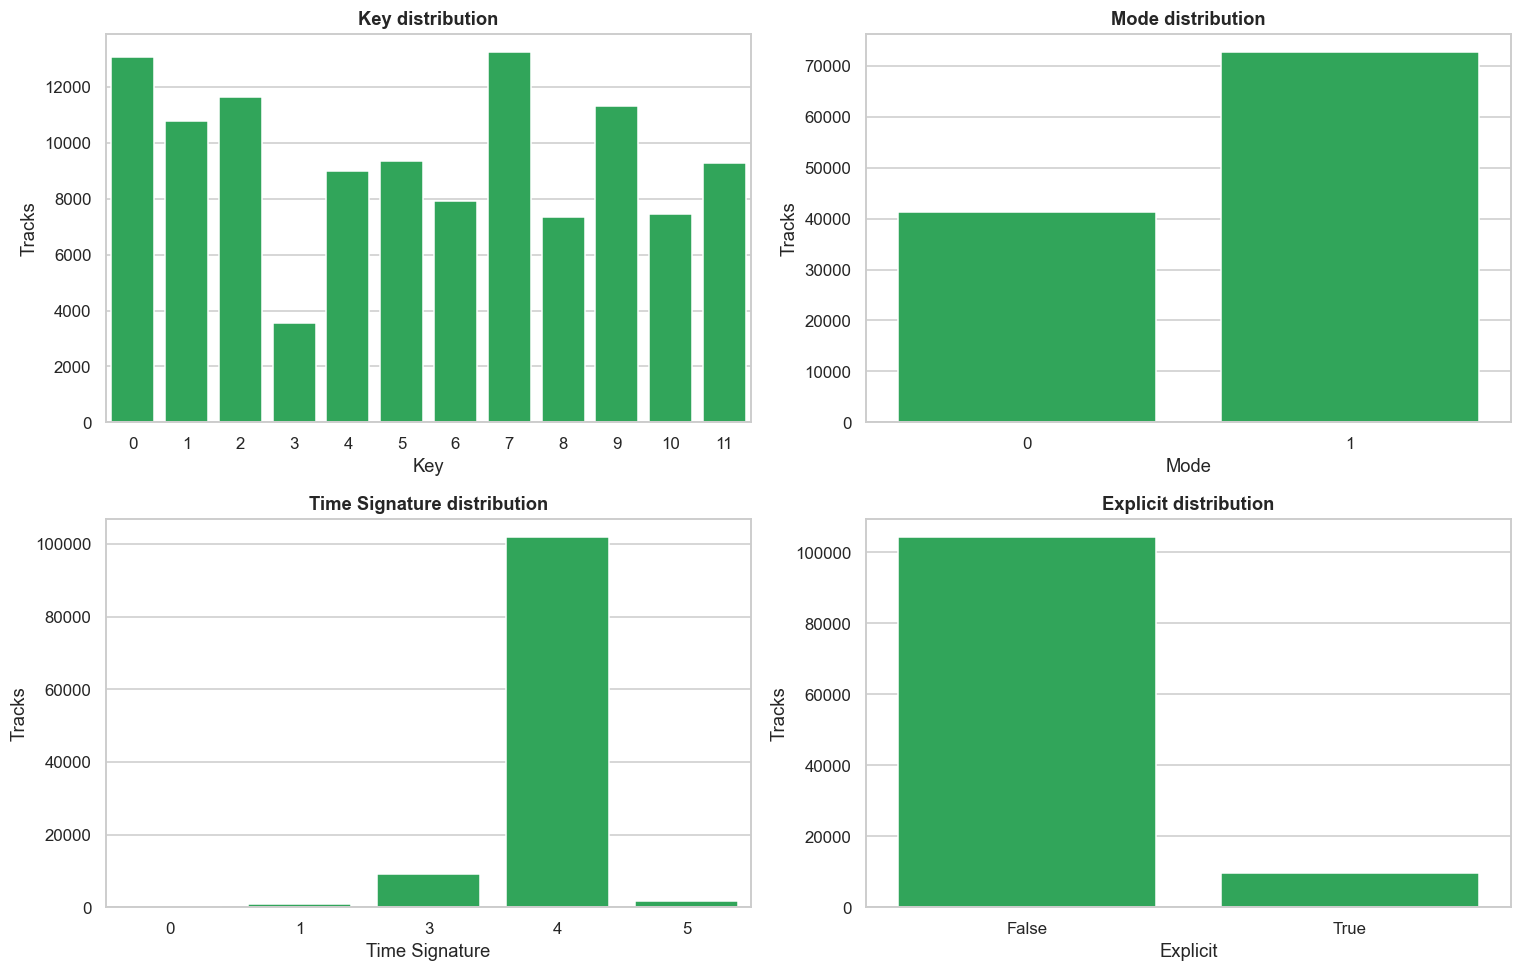

In [8]:
discrete_features = ['key', 'mode', 'time_signature', 'explicit']
discrete_features = [column for column in discrete_features if column in analysis_df.columns]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for axis, column in zip(axes.flat, discrete_features):
    counts = analysis_df[column].value_counts(dropna=False).sort_index().reset_index()
    counts.columns = [column, 'tracks']
    sns.barplot(data=counts, x=column, y='tracks', color='#1DB954', ax=axis)
    axis.set_title(f"{column.replace('_', ' ').title()} distribution")
    axis.set_xlabel(column.replace('_', ' ').title())
    axis.set_ylabel('Tracks')
    axis.set_ylim(bottom=0)
for axis in axes.flat[len(discrete_features):]:
    axis.remove()
plt.tight_layout()
plt.show()

### 4. Categorical coverage and catalog composition

,tracks_per_genre
count,114.0
mean,1000.0
std,0.0
min,1000.0
25%,1000.0
50%,1000.0
75%,1000.0
max,1000.0


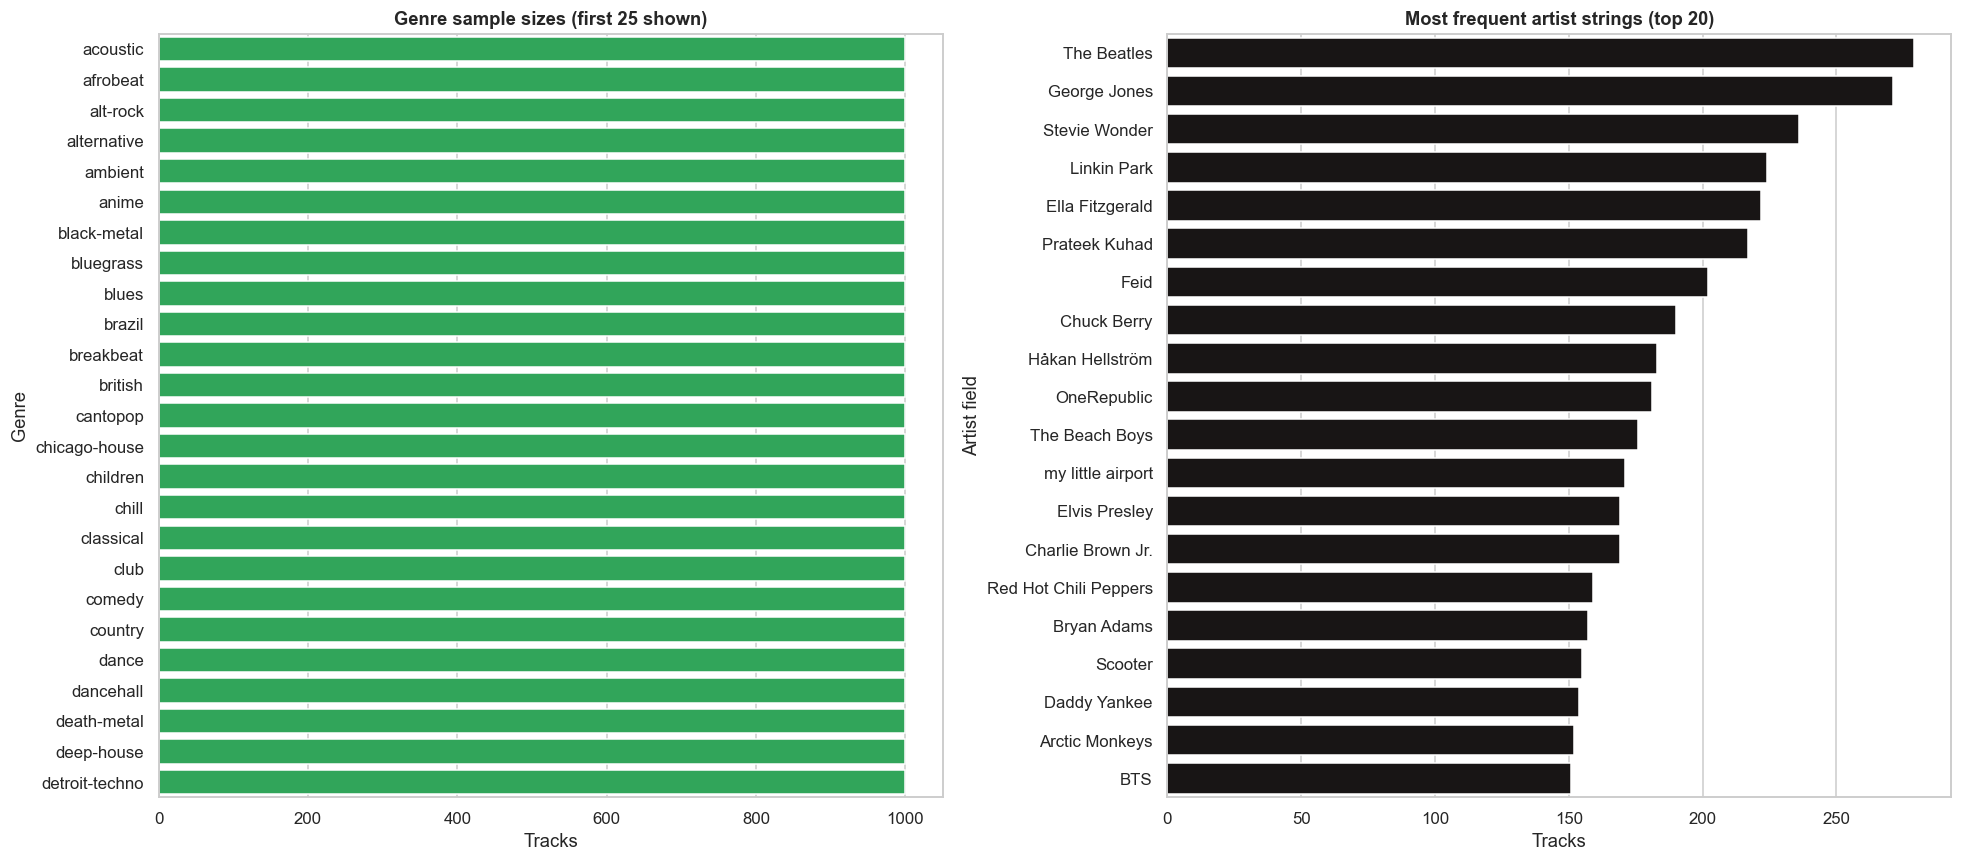

,artists,tracks
0,The Beatles,279
1,George Jones,271
2,Stevie Wonder,236
3,Linkin Park,224
4,Ella Fitzgerald,222
5,Prateek Kuhad,217
6,Feid,202
7,Chuck Berry,190
8,Håkan Hellström,183
9,OneRepublic,181


In [9]:
genre_coverage = genre_counts.rename_axis('track_genre').reset_index(name='tracks')
display(genre_coverage['tracks'].describe().to_frame('tracks_per_genre'))

# Display a bounded selection; the descriptive table above shows coverage for every genre.
genre_plot = genre_coverage.sort_values(['tracks', 'track_genre'], ascending=[False, True]).head(25)
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
sns.barplot(data=genre_plot, y='track_genre', x='tracks', color='#1DB954', ax=axes[0])
axes[0].set_title('Genre sample sizes (first 25 shown)')
axes[0].set_xlabel('Tracks')
axes[0].set_ylabel('Genre')
axes[0].set_xlim(left=0)

top_artists = (
    df['artists'].dropna().value_counts().head(20)
    .rename_axis('artists').reset_index(name='tracks')
)
sns.barplot(data=top_artists, y='artists', x='tracks', color='#191414', ax=axes[1])
axes[1].set_title('Most frequent artist strings (top 20)')
axes[1].set_xlabel('Tracks')
axes[1].set_ylabel('Artist field')
axes[1].set_xlim(left=0)
plt.tight_layout()
plt.show()

display(top_artists)

### 5. Popularity distribution and genre differences

Popularity is a dataset attribute and may be useful for business rules or candidate reranking. It should not be treated as a substitute for listening feedback.

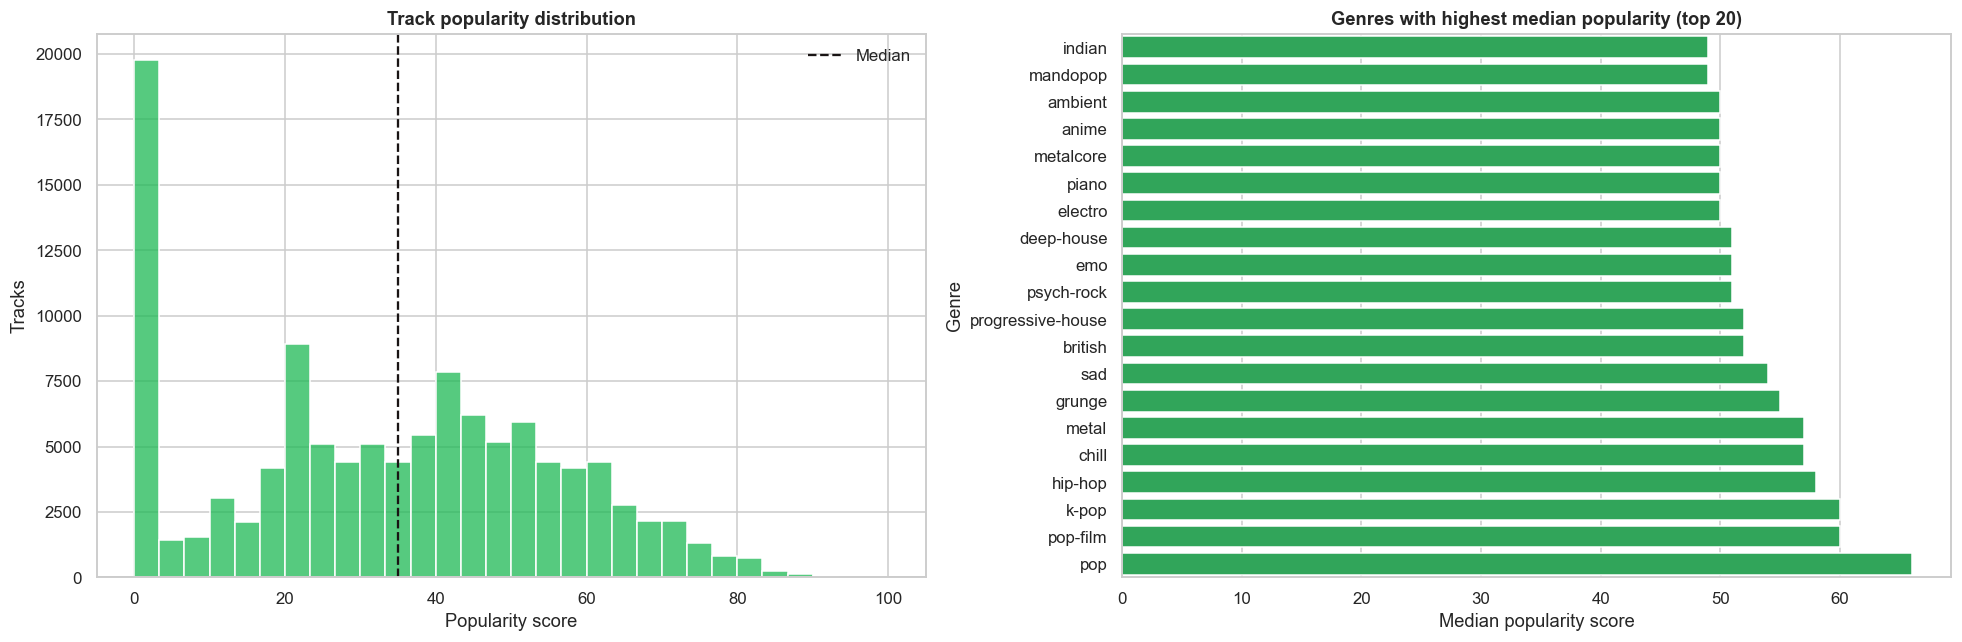

,track_genre,tracks,mean_popularity,median_popularity,std_popularity
80,pop,1000,47.58,66.0,34.04
65,k-pop,1000,56.90,60.0,16.95
81,pop-film,1000,59.28,60.0,10.25
51,hip-hop,1000,37.76,58.0,32.55
15,chill,1000,53.65,57.0,14.95
71,metal,1000,43.70,57.0,29.99
44,grunge,1000,49.59,55.0,18.49
94,sad,1000,52.38,54.0,11.49
11,british,1000,43.80,52.0,23.45
83,progressive-house,1000,46.62,52.0,20.19


,track_genre,tracks,mean_popularity,median_popularity,std_popularity
13,chicago-house,1000,12.34,10.0,9.58
24,detroit-techno,1000,11.17,8.0,8.95
16,classical,1000,13.06,3.0,18.09
88,reggae,1000,20.63,2.0,29.23
89,reggaeton,1000,23.86,2.0,31.43
68,latino,1000,25.66,2.0,31.78
3,alternative,1000,24.34,1.0,32.66
20,dance,1000,22.69,1.0,34.66
19,country,1000,17.03,0.0,27.19
59,iranian,1000,2.21,0.0,4.17


In [10]:
genre_popularity = (
    analysis_df.groupby('track_genre', as_index=False)['popularity']
    .agg(tracks='size', mean_popularity='mean', median_popularity='median', std_popularity='std')
    .sort_values('median_popularity', ascending=False)
)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
sns.histplot(data=analysis_df, x='popularity', bins=30, color='#1DB954', edgecolor='white', ax=axes[0])
axes[0].axvline(analysis_df['popularity'].median(), color='#191414', linestyle='--', label='Median')
axes[0].set_title('Track popularity distribution')
axes[0].set_xlabel('Popularity score')
axes[0].set_ylabel('Tracks')
axes[0].legend(frameon=False)

top_genres = genre_popularity.head(20).sort_values('median_popularity')
sns.barplot(data=top_genres, y='track_genre', x='median_popularity', color='#1DB954', ax=axes[1])
axes[1].set_title('Genres with highest median popularity (top 20)')
axes[1].set_xlabel('Median popularity score')
axes[1].set_ylabel('Genre')
axes[1].set_xlim(left=0)
plt.tight_layout()
plt.show()

display(genre_popularity.head(15).round(2))
display(genre_popularity.tail(15).round(2))

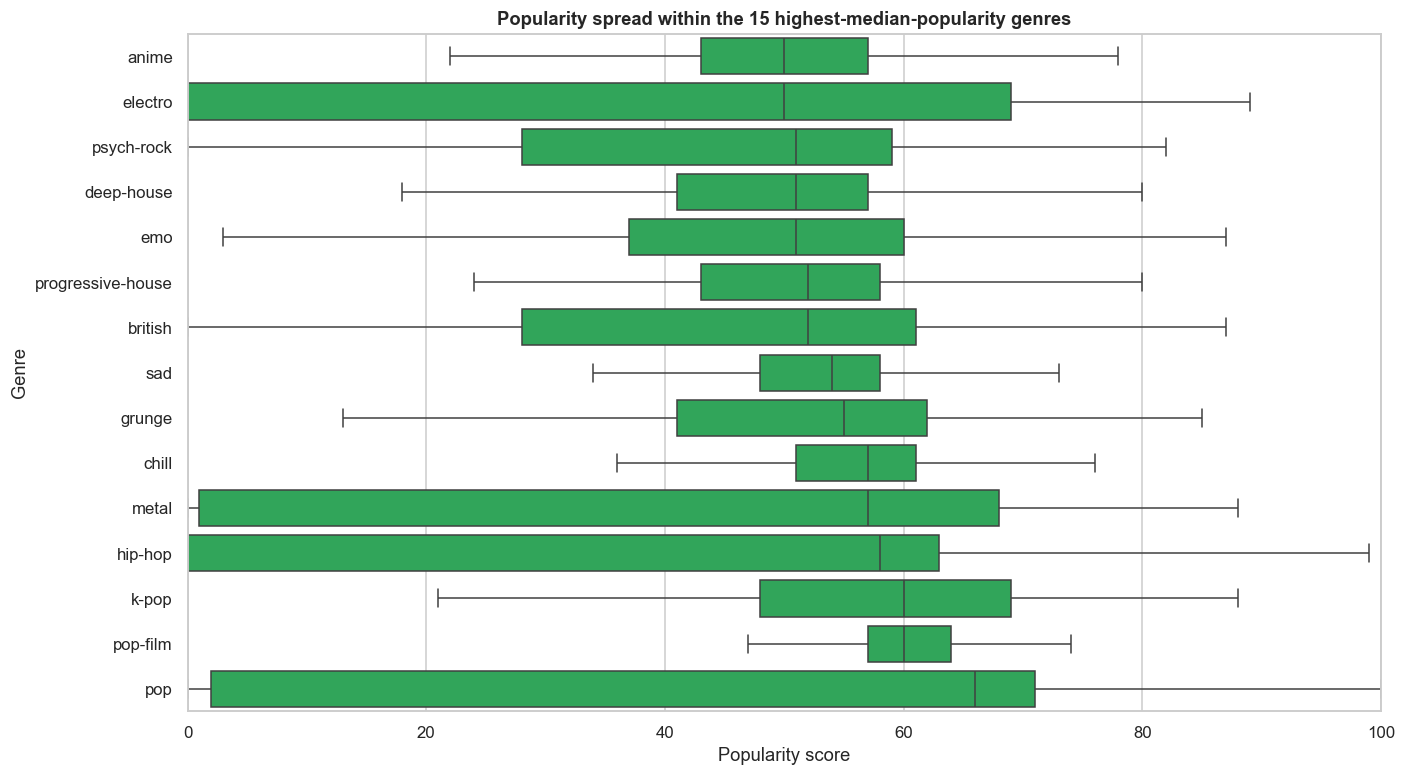

In [11]:
selected_genres = genre_popularity.head(15)['track_genre'].tolist()
boxplot_data = analysis_df[analysis_df['track_genre'].isin(selected_genres)].copy()
genre_order = genre_popularity.head(15).sort_values('median_popularity')['track_genre'].tolist()
plt.figure(figsize=(14, 8))
sns.boxplot(
    data=boxplot_data, y='track_genre', x='popularity', order=genre_order,
    color='#1DB954', showfliers=False
)
plt.title('Popularity spread within the 15 highest-median-popularity genres')
plt.xlabel('Popularity score')
plt.ylabel('Genre')
plt.xlim(0, 100)
plt.show()

### 6. Audio-feature relationships and recommendation signals

Correlation and scatterplots describe association only. They do not show which audio attributes cause a track to be popular.

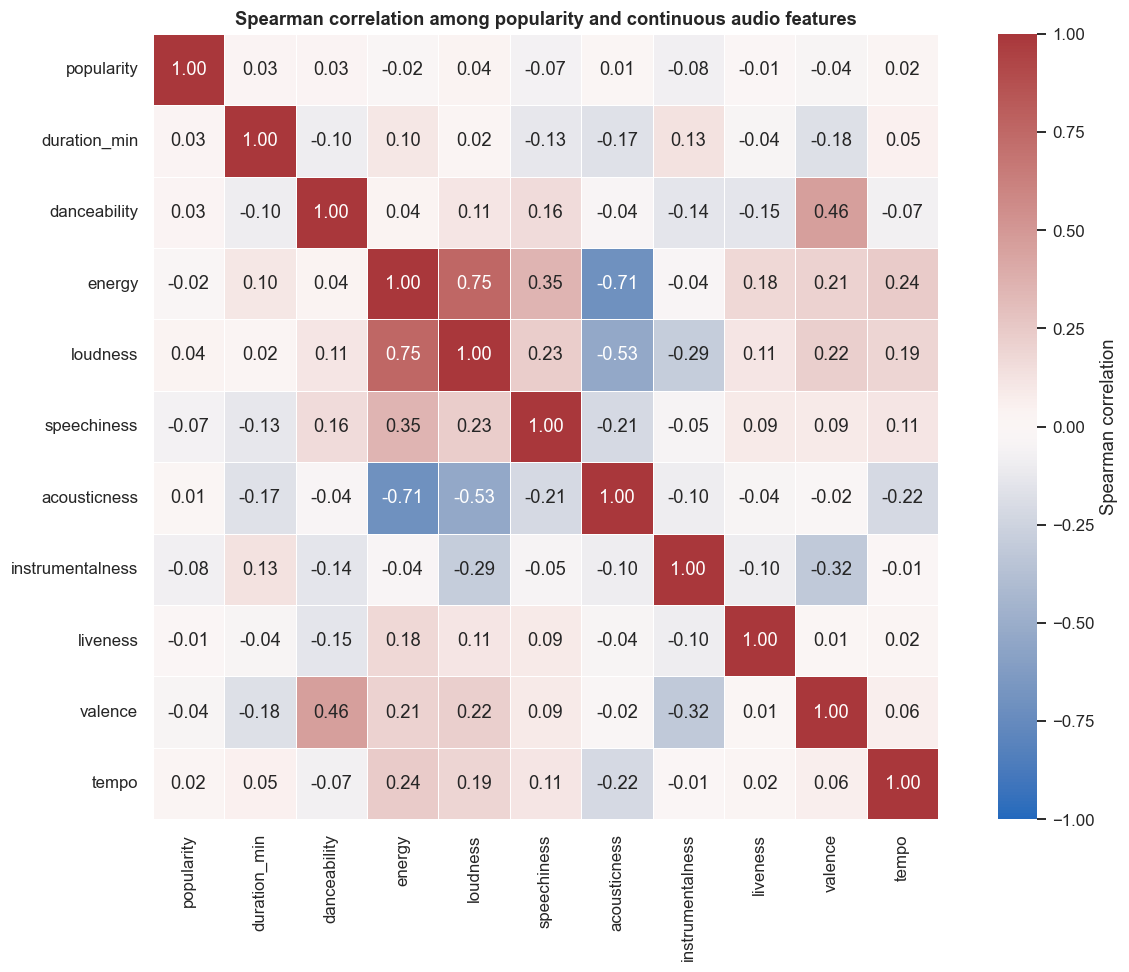

,spearman_correlation_with_popularity
instrumentalness,-0.078
speechiness,-0.068
valence,-0.042
loudness,0.035
duration_min,0.028
danceability,0.027
energy,-0.024
tempo,0.017
acousticness,0.008
liveness,-0.008


In [12]:
correlation_features = [
    'popularity', 'duration_min', 'danceability', 'energy', 'loudness',
    'speechiness', 'acousticness', 'instrumentalness', 'liveness',
    'valence', 'tempo'
]
correlation_features = [column for column in correlation_features if column in analysis_df.columns]
spearman_correlation = analysis_df[correlation_features].corr(method='spearman')

plt.figure(figsize=(12, 9))
sns.heatmap(
    spearman_correlation, cmap='vlag', vmin=-1, vmax=1, center=0,
    square=True, linewidths=0.4, cbar_kws={'label': 'Spearman correlation'}, annot=True, fmt='.2f'
)
plt.title('Spearman correlation among popularity and continuous audio features')
plt.tight_layout()
plt.show()

popularity_associations = (
    spearman_correlation['popularity'].drop('popularity')
    .sort_values(key=lambda s: s.abs(), ascending=False)
    .rename('spearman_correlation_with_popularity')
    .to_frame()
)
display(popularity_associations.round(3))

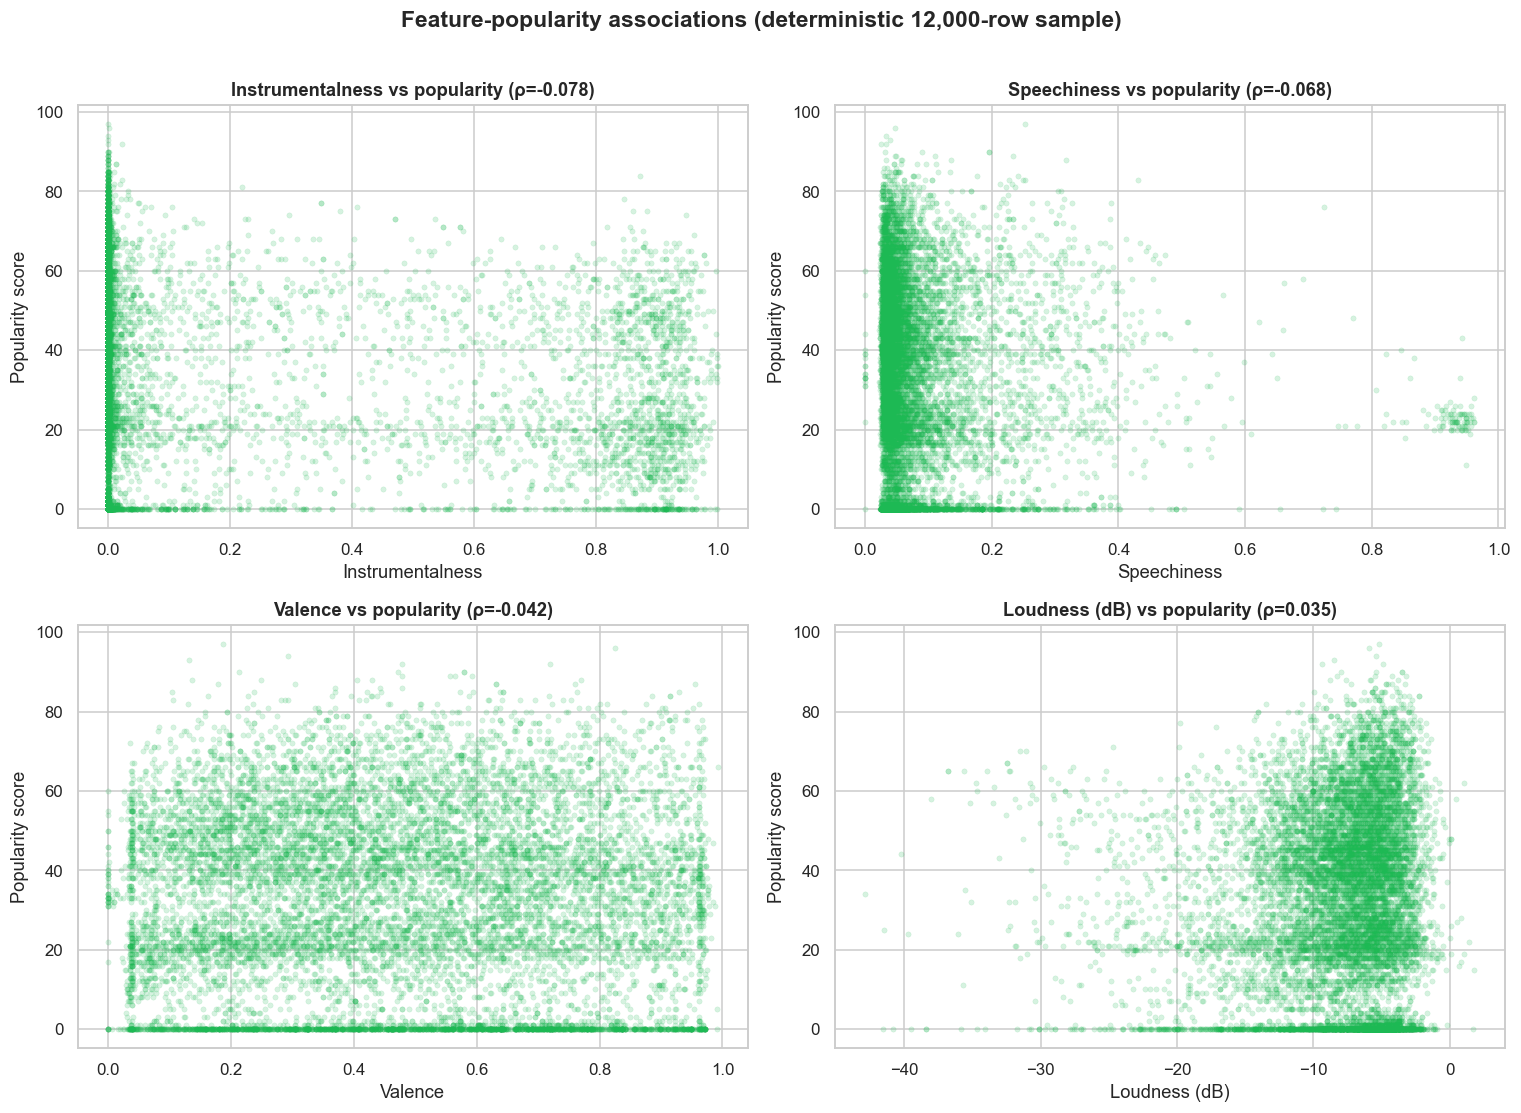

In [13]:
scatter_features = popularity_associations.index[:4].tolist()
scatter_sample = analysis_df.sample(n=min(12_000, len(analysis_df)), random_state=RANDOM_STATE)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for axis, column in zip(axes.flat, scatter_features):
    sns.scatterplot(
        data=scatter_sample, x=column, y='popularity', alpha=0.18,
        s=12, color='#1DB954', edgecolor=None, ax=axis
    )
    correlation = popularity_associations.loc[column, 'spearman_correlation_with_popularity']
    axis.set_title(f'{feature_labels.get(column, column)} vs popularity (ρ={correlation:.3f})')
    axis.set_xlabel(feature_labels.get(column, column))
    axis.set_ylabel('Popularity score')
for axis in axes.flat[len(scatter_features):]:
    axis.remove()
fig.suptitle('Feature-popularity associations (deterministic 12,000-row sample)', y=1.01, fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

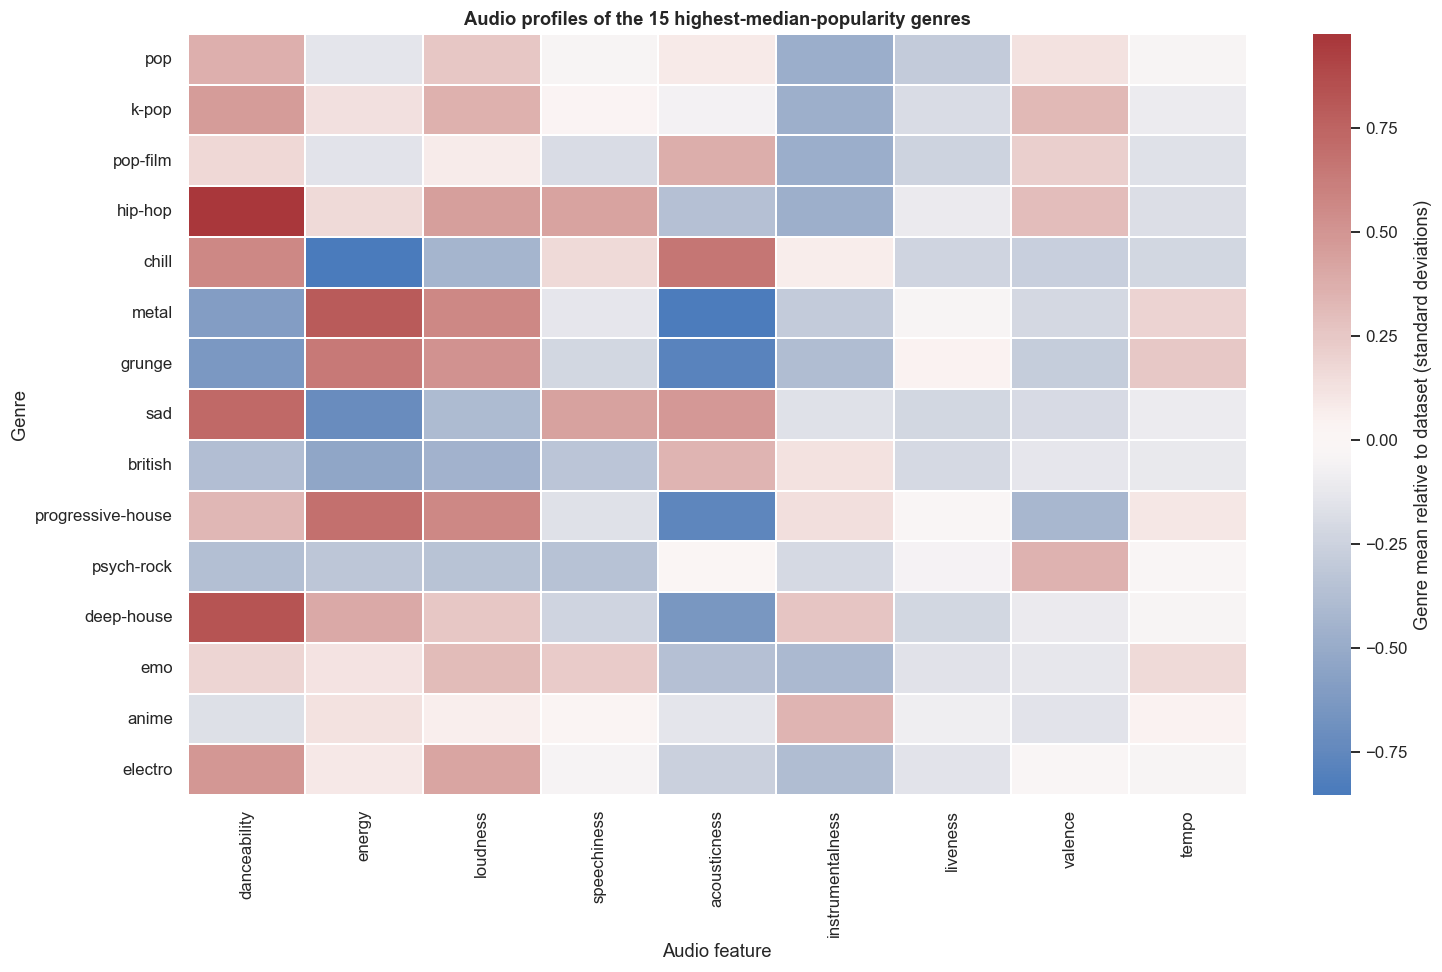

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
track_genre,,,,,,,,,
pop,0.630,0.606,-6.954,0.080,0.344,0.009,0.158,0.506,120.927
k-pop,0.648,0.676,-6.471,0.088,0.293,0.010,0.176,0.557,119.244
pop-film,0.597,0.605,-7.872,0.064,0.441,0.008,0.166,0.529,117.257
hip-hop,0.736,0.683,-5.982,0.130,0.194,0.011,0.193,0.551,116.770
chill,0.664,0.427,-10.461,0.102,0.534,0.178,0.168,0.404,115.479
metal,0.464,0.840,-5.425,0.070,0.037,0.065,0.205,0.418,127.907
grunge,0.457,0.803,-5.661,0.061,0.053,0.037,0.222,0.400,129.349
sad,0.692,0.462,-10.275,0.130,0.474,0.106,0.172,0.422,119.065
british,0.501,0.507,-10.520,0.050,0.428,0.194,0.174,0.440,118.829


In [14]:
profile_features = [
    'danceability', 'energy', 'loudness', 'speechiness', 'acousticness',
    'instrumentalness', 'liveness', 'valence', 'tempo'
]
profile_features = [column for column in profile_features if column in analysis_df.columns]
profile_genres = genre_popularity.head(15)['track_genre'].tolist()
genre_feature_means = analysis_df.groupby('track_genre')[profile_features].mean().loc[profile_genres]
feature_mean = analysis_df[profile_features].mean()
feature_std = analysis_df[profile_features].std().replace(0, np.nan)
genre_feature_zscores = (genre_feature_means - feature_mean) / feature_std

plt.figure(figsize=(14, 9))
sns.heatmap(
    genre_feature_zscores, cmap='vlag', center=0, linewidths=0.3,
    cbar_kws={'label': 'Genre mean relative to dataset (standard deviations)'}
)
plt.title('Audio profiles of the 15 highest-median-popularity genres')
plt.xlabel('Audio feature')
plt.ylabel('Genre')
plt.tight_layout()
plt.show()

display(genre_feature_means.round(3))

### 7. Content-based recommendation readiness

This dataset is suitable for an item-content baseline, subject to deduplication choices. It cannot by itself train or evaluate collaborative filtering, session-based ranking, fairness across users, or online recommendation quality.

In [15]:
candidate_features = [
    'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness',
    'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo',
    'time_signature', 'duration_min'
]
candidate_features = [column for column in candidate_features if column in analysis_df.columns]
feature_readiness = pd.DataFrame({
    'feature': candidate_features,
    'missing_rate_pct': [100 * analysis_df[column].isna().mean() for column in candidate_features],
    'zero_rate_pct': [100 * (analysis_df[column] == 0).mean() for column in candidate_features],
    'unique_values': [analysis_df[column].nunique(dropna=True) for column in candidate_features],
    'recommended_preparation': [
        'Scale robustly; inspect skew and outliers' if column in {'duration_min', 'tempo', 'loudness'}
        else 'Keep as numeric; scale before distance calculations'
        for column in candidate_features
    ]
})
display(feature_readiness.round(3))

availability = pd.DataFrame({
    'required capability': [
        'Stable item identifier', 'Content similarity features', 'Genre/category metadata',
        'User-item interactions', 'Event timestamps / sessions',
        'Impressions and negative feedback', 'Holdout evaluation split'
    ],
    'available_in_this_csv': [
        'Partial — repeated track IDs require a policy', 'Yes — audio features', 'Yes — track_genre',
        'No', 'No', 'No', 'No — must be created from interaction data'
    ],
    'implication': [
        'Decide whether track_id, track_id + genre, or a deduplicated item table defines one recommendable item.',
        'A nearest-neighbour content baseline is feasible after scaling and missing-value handling.',
        'Useful for filters or hybrid features; do not infer listener taste from genre balance.',
        'Collaborative filtering and personalisation are not possible from this file alone.',
        'No recency, session, or sequential recommendation analysis is possible.',
        'Offline ranking cannot measure exposure bias, skips, or dislikes.',
        'Obtain dated interactions and split by time or user before reporting ranking metrics.'
    ]
})
display(availability)

,feature,missing_rate_pct,zero_rate_pct,unique_values,recommended_preparation
0,danceability,0.0,0.138,1174,Keep as numeric; scale before distance calcula...
1,energy,0.0,0.001,2083,Keep as numeric; scale before distance calcula...
2,key,0.0,11.457,12,Keep as numeric; scale before distance calcula...
3,loudness,0.0,0.000,19480,Scale robustly; inspect skew and outliers
4,mode,0.0,36.245,2,Keep as numeric; scale before distance calcula...
5,speechiness,0.0,0.138,1489,Keep as numeric; scale before distance calcula...
6,acousticness,0.0,0.034,5061,Keep as numeric; scale before distance calcula...
7,instrumentalness,0.0,34.003,5346,Keep as numeric; scale before distance calcula...
8,liveness,0.0,0.002,1722,Keep as numeric; scale before distance calcula...
9,valence,0.0,0.154,1790,Keep as numeric; scale before distance calcula...


,required capability,available_in_this_csv,implication
0,Stable item identifier,Partial — repeated track IDs require a policy,"Decide whether track_id, track_id + genre, or ..."
1,Content similarity features,Yes — audio features,A nearest-neighbour content baseline is feasib...
2,Genre/category metadata,Yes — track_genre,Useful for filters or hybrid features; do not ...
3,User-item interactions,No,Collaborative filtering and personalisation ar...
4,Event timestamps / sessions,No,"No recency, session, or sequential recommendat..."
5,Impressions and negative feedback,No,"Offline ranking cannot measure exposure bias, ..."
6,Holdout evaluation split,No — must be created from interaction data,Obtain dated interactions and split by time or...


## Takeaways

In [16]:
strongest_association = popularity_associations.index[0]
strongest_rho = popularity_associations.iloc[0, 0]
max_abs_rho = popularity_associations.iloc[:, 0].abs().max()

takeaway_text = (
    f"- **Catalog coverage:** the file contains {len(df):,} records across {df['track_genre'].nunique():,} genres, each with {int(genre_counts.min()):,}–{int(genre_counts.max()):,} rows. Interpret genre-level results as comparisons within a balanced sample, not real Spotify catalog proportions.\n"
    f"- **Item identity risk:** {exact_duplicate_rows:,} rows are exact duplicates and {duplicate_track_id_rows:,} rows repeat a `track_id`. Set and document an item-level deduplication policy before candidate generation or splitting data.\n"
    f"- **Feature quality:** the audio feature set has {audio_missing:,} missing cells. Distribution and IQR screens show where robust scaling, optional winsorisation, or explicit outlier review may be useful; they do not alter the source file.\n"
    f"- **Popularity signal:** the largest absolute Spearman association with popularity among the continuous features shown is `{strongest_association}` (ρ={strongest_rho:.3f}; maximum |ρ|={max_abs_rho:.3f}). Treat these as weak descriptive associations, not ranking rules or causal effects.\n"
    f"- **Recommended next step:** build a deduplicated item table, robustly scale the approved audio features, and prototype content-nearest-neighbour retrieval. Add time-stamped user interactions before building personalised ranking or reporting offline ranking metrics."
)
display(Markdown(takeaway_text))

- **Catalog coverage:** the file contains 114,000 records across 114 genres, each with 1,000–1,000 rows. Interpret genre-level results as comparisons within a balanced sample, not real Spotify catalog proportions.
- **Item identity risk:** 450 rows are exact duplicates and 24,259 rows repeat a `track_id`. Set and document an item-level deduplication policy before candidate generation or splitting data.
- **Feature quality:** the audio feature set has 0 missing cells. Distribution and IQR screens show where robust scaling, optional winsorisation, or explicit outlier review may be useful; they do not alter the source file.
- **Popularity signal:** the largest absolute Spearman association with popularity among the continuous features shown is `instrumentalness` (ρ=-0.078; maximum |ρ|=0.078). Treat these as weak descriptive associations, not ranking rules or causal effects.
- **Recommended next step:** build a deduplicated item table, robustly scale the approved audio features, and prototype content-nearest-neighbour retrieval. Add time-stamped user interactions before building personalised ranking or reporting offline ranking metrics.

### Suggested modelling checks before training

- Define the canonical item grain and decide how the same `track_id` can appear across genre labels.
- Preserve raw audio features and fit any scaler only on a training split.
- Add user, interaction, event time, candidate exposure, and feedback data for personalised models.
- Use a time-aware or user-aware holdout set; do not use random row splitting when evaluating real recommendation behaviour.
- Evaluate retrieval and ranking separately, and inspect quality by genre, popularity band, and cold-start status.